In [ ]:
!pip -q install simpy ipywidgets

import simpy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets

from IPython.display import display, HTML, clear_output
from IPython.display import Markdown

print("All libraries are ready!")

All libraries are ready!


In [ ]:
def run_restaurant_simulation(
    arrival_rate=15,
    operating_hours=8,
    order_counters=2,
    kitchen_staff=3,
    serving_staff=2,
    seed=42
):

    # 1. Initialize random generator
    rng = np.random.default_rng(seed)

    operating_minutes = operating_hours * 60

    # 2. Generate customer arrivals using exponential distribution
    arrival_times = []
    current_time = 0

    while True:
        current_time += rng.exponential(60 / arrival_rate)

        if current_time >= operating_minutes:
            break

        arrival_times.append(current_time)

    # 3. Generate customer service durations
    customers = []

    for i, arrival in enumerate(arrival_times):
        customers.append({
            "Customer ID": i + 1,
            "Arrival Time": arrival,
            "Order Duration": rng.triangular(2, 4, 7),
            "Kitchen Duration": rng.triangular(5, 10, 18),
            "Serving Duration": rng.triangular(1, 2, 4)
        })

    # 4. Create SimPy environment and resources
    env = simpy.Environment()

    order_resource = simpy.Resource(
        env, capacity=order_counters
    )

    kitchen_resource = simpy.Resource(
        env, capacity=kitchen_staff
    )

    serving_resource = simpy.Resource(
        env, capacity=serving_staff
    )

    records = []

    busy_time = {
        "Order Counter": 0,
        "Kitchen": 0,
        "Serving Staff": 0
    }

    # 5. Define customer journey
    def customer_process(customer):

        yield env.timeout(customer["Arrival Time"])

        arrival = env.now

        # Order counter stage
        with order_resource.request() as request:
            yield request

            order_start = env.now
            order_wait = order_start - arrival

            yield env.timeout(customer["Order Duration"])

            busy_time["Order Counter"] += customer["Order Duration"]

        # Kitchen stage
        with kitchen_resource.request() as request:
            yield request

            kitchen_start = env.now

            kitchen_wait = kitchen_start - (
                order_start + customer["Order Duration"]
            )

            yield env.timeout(customer["Kitchen Duration"])

            busy_time["Kitchen"] += customer["Kitchen Duration"]

        # Serving stage
        with serving_resource.request() as request:
            yield request

            serving_start = env.now

            serving_wait = serving_start - (
                kitchen_start + customer["Kitchen Duration"]
            )

            yield env.timeout(customer["Serving Duration"])

            busy_time["Serving Staff"] += customer["Serving Duration"]

        departure = env.now

        total_wait = (
            order_wait + kitchen_wait + serving_wait
        )

        records.append({
            "Customer ID": customer["Customer ID"],
            "Arrival Time": arrival,
            "Order Start": order_start,
            "Kitchen Start": kitchen_start,
            "Serving Start": serving_start,
            "Departure Time": departure,
            "Order Waiting": order_wait,
            "Kitchen Waiting": kitchen_wait,
            "Serving Waiting": serving_wait,
            "Total Waiting": total_wait,
            "Total Time": departure - arrival
        })

    # 6. Schedule all customers
    for customer in customers:
        env.process(customer_process(customer))

    # Complete all customers, including those served after closing
    env.run()

    # 7. Create customer results table
    df = pd.DataFrame(records)

    if df.empty:
        raise ValueError("No customers generated. Increase arrival rate or operating hours.")

    # 8. Calculate resource utilization
    capacities = {
        "Order Counter": order_counters,
        "Kitchen": kitchen_staff,
        "Serving Staff": serving_staff
    }

    simulation_duration = env.now

    utilization = {}

    for stage, capacity in capacities.items():
        utilization[stage] = (
            busy_time[stage] /
            (capacity * simulation_duration) * 100
        )

    # 9. Calculate performance summary
    summary = {
        "Customers Arrived": len(customers),
        "Customers Served": len(df),
        "Average Total Waiting": df["Total Waiting"].mean(),
        "Average Restaurant Time": df["Total Time"].mean(),
        "Maximum Waiting Time": df["Total Waiting"].max(),
        "Average Order Waiting": df["Order Waiting"].mean(),
        "Average Kitchen Waiting": df["Kitchen Waiting"].mean(),
        "Average Serving Waiting": df["Serving Waiting"].mean(),
        "Order Counter Utilization": utilization["Order Counter"],
        "Kitchen Utilization": utilization["Kitchen"],
        "Serving Staff Utilization": utilization["Serving Staff"],
        "Customers Waiting Over 10 Min": (
            df["Total Waiting"] > 10
        ).sum(),
        "Simulation Duration": simulation_duration
    }

    return df, summary


print("Restaurant simulation engine successfully defined!")

Restaurant simulation engine successfully defined!


In [ ]:
df, summary = run_restaurant_simulation(
    arrival_rate=15,
    operating_hours=8,
    order_counters=2,
    kitchen_staff=3,
    serving_staff=2,
    seed=42
)

print("RESTAURANT SIMULATION RESULTS")
print("=" * 40)

for key, value in summary.items():
    if isinstance(value, (int, np.integer)):
        print(f"{key}: {value}")
    else:
        print(f"{key}: {value:.2f}")

display(df.head(10))

RESTAURANT SIMULATION RESULTS
Customers Arrived: 131
Customers Served: 131
Average Total Waiting: 17.45
Average Restaurant Time: 35.02
Maximum Waiting Time: 43.54
Average Order Waiting: 1.53
Average Kitchen Waiting: 15.90
Average Serving Waiting: 0.01
Order Counter Utilization: 56.06
Kitchen Utilization: 92.80
Serving Staff Utilization: 29.51
Customers Waiting Over 10 Min: 96
Simulation Duration: 512.13


,Customer ID,Arrival Time,Order Start,Kitchen Start,Serving Start,Departure Time,Order Waiting,Kitchen Waiting,Serving Waiting,Total Waiting,Total Time
0,1,9.616834,9.616834,14.110027,23.858347,26.291660,0.000000,0.000000,0.0,0.000000,16.674825
1,2,18.961593,18.961593,21.439127,37.363111,39.600676,0.000000,0.000000,0.0,0.000000,20.639082
2,3,28.500637,28.500637,33.695375,41.014308,43.259301,0.000000,0.000000,0.0,0.000000,14.758664
3,5,29.965564,33.695375,37.885097,47.050841,49.048191,3.729811,0.000000,0.0,3.729811,19.082627
4,4,29.619814,29.619814,33.855869,49.313026,51.710019,0.000000,0.000000,0.0,0.000000,22.090205
5,6,35.776206,35.776206,41.014308,51.375381,52.630010,0.000000,0.919503,0.0,0.919503,16.853804
6,7,41.416049,41.416049,47.050841,61.764615,63.413265,0.000000,0.248986,0.0,0.248986,21.997217
7,8,53.913232,53.913232,58.326834,65.983415,68.581074,0.000000,0.000000,0.0,0.000000,14.667842
8,11,58.698398,58.698398,62.215678,68.775106,71.140822,0.000000,0.000000,0.0,0.000000,12.442424
9,9,54.230409,54.230409,57.907412,69.955938,72.676081,0.000000,0.000000,0.0,0.000000,18.445672


In [ ]:
# RESTAURANT OPERATIONS DASHBOARD

# Input controls
arrival_input = widgets.IntSlider(
    value=15, min=5, max=35, step=1,
    description="Customers/hr:"
)

hours_input = widgets.IntSlider(
    value=8, min=2, max=12,
    description="Hours:"
)

order_input = widgets.IntSlider(
    value=2, min=1, max=6,
    description="Order staff:"
)

kitchen_input = widgets.IntSlider(
    value=3, min=1, max=8,
    description="Kitchen staff:"
)

serving_input = widgets.IntSlider(
    value=2, min=1, max=6,
    description="Serving staff:"
)

run_button = widgets.Button(
    description="RUN SIMULATION",
    button_style="success",
    icon="play",
    layout=widgets.Layout(width="200px", height="40px")
)

dashboard_output = widgets.Output()

def show_dashboard(change=None):

    with dashboard_output:
        clear_output(wait=True)

        result_df, result = run_restaurant_simulation(
            arrival_rate=arrival_input.value,
            operating_hours=hours_input.value,
            order_counters=order_input.value,
            kitchen_staff=kitchen_input.value,
            serving_staff=serving_input.value,
            seed=42
        )

        stages = ["Order Counter", "Kitchen", "Serving Staff"]

        waits = [
            result["Average Order Waiting"],
            result["Average Kitchen Waiting"],
            result["Average Serving Waiting"]
        ]

        utilization = [
            result["Order Counter Utilization"],
            result["Kitchen Utilization"],
            result["Serving Staff Utilization"]
        ]

        bottleneck_index = int(np.argmax(waits))
        bottleneck = stages[bottleneck_index]

        # Dashboard heading
        display(HTML("""
        <div style="background:#34251f;padding:22px;border-radius:12px;
        color:white;margin-bottom:15px;">
        <h1 style="margin:0;color:#ffffff;">RESTAURANT OPERATIONS</h1>
        <p style="margin:6px 0 0;color:#f2c99b;">
        Simulation and Performance Analytics
        </p></div>
        """))

        # KPI cards
        cards = [
            ("Customers Served", f'{result["Customers Served"]}', "#e9f2ee"),
            ("Average Waiting", f'{result["Average Total Waiting"]:.2f} min', "#fff0df"),
            ("Time in Restaurant", f'{result["Average Restaurant Time"]:.2f} min', "#e9eef8"),
            ("Bottleneck", bottleneck, "#f8e9e5")
        ]

        card_html = '<div style="display:grid;grid-template-columns:repeat(2,1fr);gap:12px;">'

        for label, value, color in cards:
            card_html += f"""
            <div style="background:{color};padding:18px;border-radius:10px;">
            <div style="font-size:13px;color:#51443d;">{label}</div>
            <div style="font-size:23px;font-weight:bold;color:#34251f;">{value}</div>
            </div>
            """

        card_html += "</div>"

        display(HTML(card_html))

        # Graphs
        fig, axes = plt.subplots(1, 2, figsize=(13, 4))

        axes[0].bar(stages, waits, color=["#d9a15b", "#bd6548", "#588b78"])
        axes[0].set_title("Average Waiting by Stage")
        axes[0].set_ylabel("Minutes")
        axes[0].tick_params(axis="x", rotation=15)

        for i, value in enumerate(waits):
            axes[0].text(i, value, f"{value:.1f}", ha="center", va="bottom")

        axes[1].barh(stages, utilization, color=["#d9a15b", "#bd6548", "#588b78"])
        axes[1].set_title("Resource Utilization")
        axes[1].set_xlabel("Utilization (%)")
        axes[1].set_xlim(0, 110)

        for i, value in enumerate(utilization):
            axes[1].text(value + 1, i, f"{value:.1f}%")

        plt.tight_layout()
        plt.show()

        # Analysis and recommendation
        bottleneck_wait = waits[bottleneck_index]
        bottleneck_util = utilization[bottleneck_index]

        if bottleneck_util >= 85 and bottleneck_wait > 2:
            recommendation = (
                f"Consider increasing capacity at the {bottleneck}. "
                "Run another simulation with additional staff and compare results."
            )
        elif bottleneck_wait > 2:
            recommendation = (
                f"The {bottleneck} has the highest waiting time. "
                "Investigate its service process before increasing staffing."
            )
        else:
            recommendation = (
                "No major queueing bottleneck is visible in this scenario. "
                "Current staffing appears reasonably balanced."
            )

        display(HTML(f"""
        <div style="background:#f5eee5;padding:18px;border-radius:10px;
        margin-top:12px;color:#34251f;">
        <h3>MANAGER'S INSIGHT</h3>
        <p><b>Primary bottleneck:</b> {bottleneck}</p>
        <p><b>Average waiting at this stage:</b> {bottleneck_wait:.2f} minutes</p>
        <p><b>Utilization:</b> {bottleneck_util:.2f}%</p>
        <p><b>Recommendation:</b> {recommendation}</p>
        </div>
        """))

        # Detailed data
        display(Markdown("### Customer-level simulation results"))
        display(result_df.sort_values("Customer ID").head(10))

        # Downloadable results
        csv_data = result_df.to_csv(index=False).encode("utf-8")

        display(widgets.Button(
            description="CSV results are ready",
            disabled=True
        ))

        print("Simulation completed successfully.")


run_button.on_click(show_dashboard)

controls = widgets.VBox([
    widgets.HTML("<h2 style='color:#34251f'>Simulation Settings</h2>"),
    arrival_input,
    hours_input,
    order_input,
    kitchen_input,
    serving_input,
    run_button
])

display(controls)
display(dashboard_output)

Output()

RESTAURANT STAFFING SCENARIO COMPARISON


,Scenario,Order Staff,Kitchen Staff,Serving Staff,Customers Served,Average Waiting (min),Restaurant Time (min),Order Utilization (%),Kitchen Utilization (%),Serving Utilization (%)
0,Understaffed,1,2,1,131,126.81,144.38,77.54,96.28,40.82
1,Current Setup,2,3,2,131,17.45,35.02,56.06,92.80,29.51
2,Improved Setup,2,5,2,131,1.88,19.45,57.93,57.54,30.50


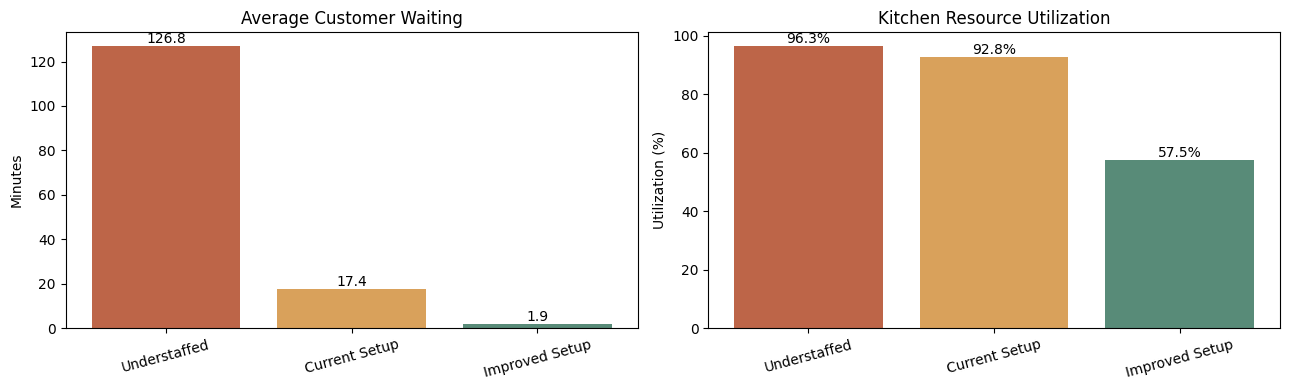

Waiting-time reduction after improving staffing: 89.23%

MANAGER'S DECISION
Lowest waiting time: Improved Setup
Average waiting: 1.88 minutes
Compare staffing cost as well before choosing a final arrangement.


In [ ]:
# SCENARIO COMPARISON ANALYSIS

scenarios = {
    "Understaffed": {
        "order_counters": 1,
        "kitchen_staff": 2,
        "serving_staff": 1
    },
    "Current Setup": {
        "order_counters": 2,
        "kitchen_staff": 3,
        "serving_staff": 2
    },
    "Improved Setup": {
        "order_counters": 2,
        "kitchen_staff": 5,
        "serving_staff": 2
    }
}

scenario_results = []

for name, staff in scenarios.items():

    scenario_df, result = run_restaurant_simulation(
        arrival_rate=arrival_input.value,
        operating_hours=hours_input.value,
        order_counters=staff["order_counters"],
        kitchen_staff=staff["kitchen_staff"],
        serving_staff=staff["serving_staff"],
        seed=42
    )

    scenario_results.append({
        "Scenario": name,
        "Order Staff": staff["order_counters"],
        "Kitchen Staff": staff["kitchen_staff"],
        "Serving Staff": staff["serving_staff"],
        "Customers Served": result["Customers Served"],
        "Average Waiting (min)": result["Average Total Waiting"],
        "Restaurant Time (min)": result["Average Restaurant Time"],
        "Order Utilization (%)": result["Order Counter Utilization"],
        "Kitchen Utilization (%)": result["Kitchen Utilization"],
        "Serving Utilization (%)": result["Serving Staff Utilization"]
    })

comparison_df = pd.DataFrame(scenario_results)

print("RESTAURANT STAFFING SCENARIO COMPARISON")
display(comparison_df.round(2))

# Calculate improvement
baseline = comparison_df.loc[
    comparison_df["Scenario"] == "Current Setup",
    "Average Waiting (min)"
].iloc[0]

improved = comparison_df.loc[
    comparison_df["Scenario"] == "Improved Setup",
    "Average Waiting (min)"
].iloc[0]

reduction = (
    (baseline - improved) / baseline * 100
    if baseline > 0 else 0
)

# Visual comparison
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].bar(
    comparison_df["Scenario"],
    comparison_df["Average Waiting (min)"],
    color=["#BD6548", "#D9A15B", "#588B78"]
)
axes[0].set_title("Average Customer Waiting")
axes[0].set_ylabel("Minutes")
axes[0].tick_params(axis="x", rotation=15)

for i, value in enumerate(comparison_df["Average Waiting (min)"]):
    axes[0].text(i, value, f"{value:.1f}", ha="center", va="bottom")

axes[1].bar(
    comparison_df["Scenario"],
    comparison_df["Kitchen Utilization (%)"],
    color=["#BD6548", "#D9A15B", "#588B78"]
)
axes[1].set_title("Kitchen Resource Utilization")
axes[1].set_ylabel("Utilization (%)")
axes[1].tick_params(axis="x", rotation=15)

for i, value in enumerate(comparison_df["Kitchen Utilization (%)"]):
    axes[1].text(i, value, f"{value:.1f}%", ha="center", va="bottom")

plt.tight_layout()
plt.show()

print(f"Waiting-time reduction after improving staffing: {reduction:.2f}%")

best = comparison_df.loc[
    comparison_df["Average Waiting (min)"].idxmin()
]

print("\nMANAGER'S DECISION")
print(f"Lowest waiting time: {best['Scenario']}")
print(f"Average waiting: {best['Average Waiting (min)']:.2f} minutes")
print("Compare staffing cost as well before choosing a final arrangement.")

In [ ]:
# Export project results

df.to_csv("customer_results.csv", index=False)
comparison_df.to_csv("scenario_comparison.csv", index=False)

print("Both CSV files saved successfully!")

Both CSV files saved successfully!


In [ ]:
!pip -q install gradio plotly

In [ ]:

# ================================================================
# FINAL RESTAURANT OPERATIONS SIMULATOR DASHBOARD
#
# IMPORTANT:
# 1. Keep your existing simulation engine in Cell 2.
# 2. Replace your previous Gradio dashboard cell with this cell.
# 3. Run Cell 2 first, then run this cell.
# ================================================================

import gradio as gr
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tempfile
import os
from datetime import datetime
from html import escape

# ------------------------- DESIGN -------------------------

CUSTOM_CSS = """
.gradio-container {
    max-width: 1500px !important;
    margin: auto !important;
    background: #f7f7f4 !important;
    font-family: Inter, Arial, sans-serif !important;
}

#page-header {
    background: #20334d;
    color: #ffffff;
    padding: 27px 32px;
    border-radius: 9px;
    margin-bottom: 20px;
}

#page-header h1 {
    color: white !important;
    font-size: 27px !important;
    font-weight: 700 !important;
    margin: 0 0 8px 0 !important;
}

#page-header p {
    color: #dce5ed !important;
    font-size: 14px;
    margin: 0;
}

.section-title {
    color: #26384c;
    font-size: 18px;
    font-weight: 700;
    margin: 12px 0;
}

.muted {
    color: #75808c;
    font-size: 12px;
    line-height: 1.6;
}

.kpi-grid {
    display: grid;
    grid-template-columns: repeat(4, minmax(0, 1fr));
    gap: 12px;
    margin: 10px 0 20px 0;
}

.kpi-card {
    background: #ffffff;
    border: 1px solid #e4e7e9;
    border-radius: 8px;
    padding: 17px;
}

.kpi-label {
    color: #737d87;
    font-size: 11px;
    font-weight: 700;
    letter-spacing: .35px;
    text-transform: uppercase;
}

.kpi-value {
    color: #20334d;
    font-size: 25px;
    font-weight: 750;
    margin-top: 9px;
}

.kpi-note {
    color: #818b95;
    font-size: 11px;
    margin-top: 5px;
}

.insight {
    background: #ffffff;
    border: 1px solid #e2e7e9;
    border-left: 4px solid #527b72;
    border-radius: 7px;
    padding: 16px 18px;
    margin: 10px 0;
    color: #354454;
    line-height: 1.65;
    font-size: 13px;
}

.notice {
    background: #f0f4f5;
    border: 1px solid #dce5e7;
    border-radius: 7px;
    padding: 14px 17px;
    margin: 10px 0;
    color: #405363;
    line-height: 1.6;
    font-size: 13px;
}

.recommendation {
    background: #edf4ef;
    border: 1px solid #d4e3d8;
    border-radius: 8px;
    padding: 20px;
    color: #294b3b;
    line-height: 1.7;
    margin: 10px 0 18px 0;
}

.recommendation h3 {
    color: #294b3b;
    margin-top: 0;
}

.recommendation .big {
    font-size: 27px;
    font-weight: 750;
}

.comparison-table {
    width: 100%;
    border-collapse: collapse;
    background: white;
    font-size: 12px;
    margin: 12px 0;
}

.comparison-table th {
    background: #e9eef0;
    color: #354454;
    text-align: left;
    padding: 12px 9px;
    font-weight: 700;
}

.comparison-table td {
    border-bottom: 1px solid #e9edef;
    padding: 12px 9px;
    color: #40505e;
}

.comparison-table tr:last-child td {
    border-bottom: none;
}

.comparison-table .recommended-row {
    background: #f0f6f1;
    font-weight: 650;
}

.category-grid {
    display: grid;
    grid-template-columns: repeat(3, minmax(0, 1fr));
    gap: 10px;
    margin: 12px 0;
}

.category-card {
    border-radius: 8px;
    padding: 16px;
    background: white;
    border: 1px solid #e5e8e8;
}

.category-card .number {
    font-size: 25px;
    font-weight: 750;
    margin: 5px 0;
}

.category-card .description {
    color: #77828b;
    font-size: 11px;
}

.green { color: #397b5b; }
.amber { color: #ae792b; }
.red { color: #b75c52; }

#run-button {
    min-height: 48px;
    font-weight: 700;
    letter-spacing: .2px;
}

footer {
    color: #87919a;
}

@media (max-width: 750px) {
    .kpi-grid {
        grid-template-columns: repeat(2, minmax(0, 1fr));
    }
    .category-grid {
        grid-template-columns: repeat(3, minmax(0, 1fr));
    }
}
"""

# ------------------------- HELPERS -------------------------

REPETITIONS = 5


def run_repeated_simulation(
    arrival_rate,
    operating_hours,
    order_staff,
    kitchen_staff,
    serving_staff
):
    """
    Runs five simulations using different seeds.
    Returns the first run's customer records and the
    average of numerical summary metrics.
    """
    summaries = []
    first_run_df = None

    for seed in range(42, 42 + REPETITIONS):
        df, summary = run_restaurant_simulation(
            arrival_rate=int(arrival_rate),
            operating_hours=int(operating_hours),
            order_counters=int(order_staff),
            kitchen_staff=int(kitchen_staff),
            serving_staff=int(serving_staff),
            seed=seed
        )

        summaries.append(summary)

        if first_run_df is None:
            first_run_df = df.copy()

    averaged = {}

    for key in summaries[0]:
        values = [s[key] for s in summaries]

        if all(
            isinstance(v, (int, float, np.integer, np.floating))
            for v in values
        ):
            averaged[key] = float(np.mean(values))
        else:
            averaged[key] = values[0]

    return first_run_df, averaged


def calculate_staff_cost(
    summary,
    order_count,
    kitchen_count,
    serving_count,
    order_shift_cost,
    kitchen_shift_cost,
    serving_shift_cost
):
    """
    Cost assumptions are entered per employee for an 8-hour shift.
    They are converted to an hourly equivalent and multiplied by
    the simulation's elapsed duration.
    """
    shift_cost = (
        order_count * order_shift_cost
        + kitchen_count * kitchen_shift_cost
        + serving_count * serving_shift_cost
    )

    elapsed_hours = summary["Simulation Duration"] / 60

    return (shift_cost / 8) * elapsed_hours


def make_chart(title, xlabel, ylabel):
    fig, ax = plt.subplots(figsize=(8, 4.2))
    fig.patch.set_facecolor("#ffffff")
    ax.set_facecolor("#ffffff")

    ax.set_title(
        title,
        fontsize=13,
        fontweight="bold",
        color="#26384c",
        pad=14
    )

    ax.set_xlabel(xlabel, color="#596875")
    ax.set_ylabel(ylabel, color="#596875")
    ax.grid(axis="y", alpha=0.18)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    return fig, ax


def money(value):
    return f"₹{value:,.0f}"


# ------------------------- DASHBOARD LOGIC -------------------------

def run_dashboard(
    arrival_rate,
    operating_hours,
    order_staff,
    kitchen_staff,
    serving_staff,
    target_wait,
    order_shift_cost,
    kitchen_shift_cost,
    serving_shift_cost
):

    try:
        # Check the cost inputs.
        if min(
            order_shift_cost,
            kitchen_shift_cost,
            serving_shift_cost
        ) < 0:
            raise ValueError("Staffing costs cannot be negative.")

        # ========================================================
        # 1. CURRENT STAFFING SIMULATION
        # ========================================================

        customer_df, current = run_repeated_simulation(
            arrival_rate,
            operating_hours,
            order_staff,
            kitchen_staff,
            serving_staff
        )

        current_cost = calculate_staff_cost(
            current,
            order_staff,
            kitchen_staff,
            serving_staff,
            order_shift_cost,
            kitchen_shift_cost,
            serving_shift_cost
        )

        avg_wait = current["Average Total Waiting"]
        avg_time = current["Average Restaurant Time"]
        customers_served = current["Customers Served"]
        max_wait = current["Maximum Waiting Time"]

        # ========================================================
        # 2. KPI CARDS
        # ========================================================

        kpi_html = f"""
        <div class="kpi-grid">
            <div class="kpi-card">
                <div class="kpi-label">Customers served</div>
                <div class="kpi-value">{customers_served:.0f}</div>
                <div class="kpi-note">Average across 5 runs</div>
            </div>

            <div class="kpi-card">
                <div class="kpi-label">Average waiting time</div>
                <div class="kpi-value">{avg_wait:.1f} min</div>
                <div class="kpi-note">Waiting across all service queues</div>
            </div>

            <div class="kpi-card">
                <div class="kpi-label">Restaurant time</div>
                <div class="kpi-value">{avg_time:.1f} min</div>
                <div class="kpi-note">Arrival to service completion</div>
            </div>

            <div class="kpi-card">
                <div class="kpi-label">Maximum waiting time</div>
                <div class="kpi-value">{max_wait:.1f} min</div>
                <div class="kpi-note">Average of maximum waits per run</div>
            </div>
        </div>
        """

        # ========================================================
        # 3. BOTTLENECK ANALYSIS
        # ========================================================

        stage_waits = {
            "Order Counter": current["Average Order Waiting"],
            "Kitchen": current["Average Kitchen Waiting"],
            "Serving Staff": current["Average Serving Waiting"]
        }

        utilization = {
            "Order Counter": current["Order Counter Utilization"],
            "Kitchen": current["Kitchen Utilization"],
            "Serving Staff": current["Serving Staff Utilization"]
        }

        bottleneck = max(stage_waits, key=stage_waits.get)

        total_stage_wait = sum(stage_waits.values())

        bottleneck_share = (
            stage_waits[bottleneck] / total_stage_wait * 100
            if total_stage_wait > 0 else 0
        )

        busiest_resource = max(utilization, key=utilization.get)

        diagnosis = f"""
<div class="insight">
<strong>Primary bottleneck: {bottleneck}</strong><br>
Customers spend an average of
<strong>{stage_waits[bottleneck]:.1f} minutes</strong>
waiting at this stage. It contributes approximately
<strong>{bottleneck_share:.1f}%</strong> of the total stage waiting time.
<br><br>
<strong>Manager's interpretation:</strong> This stage is the main source
of delays in the current simulation. Increasing its capacity is a
reasonable first experiment.
</div>

<div class="insight">
<strong>Resource utilisation</strong><br>
The highest resource utilisation is at
<strong>{busiest_resource}</strong>
({utilization[busiest_resource]:.1f}%).
<br><br>
Utilisation measures how much of the available resource capacity was
occupied during the simulated elapsed time. High utilisation together
with high waiting time can indicate a capacity problem.
</div>
"""

        if avg_wait <= target_wait:
            diagnosis += f"""
<div class="notice">
<strong>Waiting-time target achieved.</strong><br>
The current staffing plan has an average wait of {avg_wait:.1f} minutes,
within your selected target of {target_wait:.0f} minutes.
</div>
"""
        else:
            diagnosis += f"""
<div class="notice">
<strong>Waiting-time target not achieved.</strong><br>
The current plan averages {avg_wait:.1f} minutes, above your target
of {target_wait:.0f} minutes. Review the staffing and demand experiments.
</div>
"""

        # ========================================================
        # 4. SERVICE STAGE WAITING CHART
        # ========================================================

        fig_stage, ax_stage = make_chart(
            "Average Waiting Time by Service Stage",
            "Service stage",
            "Waiting time (minutes)"
        )

        stage_names = list(stage_waits.keys())
        stage_values = list(stage_waits.values())

        bars = ax_stage.bar(
            stage_names,
            stage_values,
            color=["#7894a8", "#d69a55", "#719b87"],
            width=0.55
        )

        for bar, value in zip(bars, stage_values):
            ax_stage.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 0.2,
                f"{value:.1f}",
                ha="center",
                fontsize=10
            )

        fig_stage.tight_layout()

        # ========================================================
        # 5. RESOURCE UTILISATION CHART
        # ========================================================

        fig_util, ax_util = make_chart(
            "Staff Resource Utilisation",
            "Resource",
            "Utilisation (%)"
        )

        ax_util.bar(
            list(utilization.keys()),
            list(utilization.values()),
            color=["#7894a8", "#d69a55", "#719b87"],
            width=0.55
        )

        ax_util.axhline(
            80,
            linestyle="--",
            color="#b85d52",
            linewidth=1.3,
            label="80% reference"
        )

        ax_util.set_ylim(
            0,
            max(110, max(utilization.values()) + 10)
        )

        ax_util.legend(frameon=False)
        fig_util.tight_layout()

        # ========================================================
        # 6. CUSTOMER EXPERIENCE ANALYSIS
        # ========================================================

        # This uses actual customer records from the first run.
        waits = customer_df["Total Waiting"].dropna()

        under_10 = int((waits < 10).sum())
        from_10_to_20 = int(((waits >= 10) & (waits <= 20)).sum())
        over_20 = int((waits > 20).sum())

        total_customers = len(waits)

        def percentage(count):
            return (
                count / total_customers * 100
                if total_customers else 0
            )

        p1 = percentage(under_10)
        p2 = percentage(from_10_to_20)
        p3 = percentage(over_20)

        customer_html = f"""
<div class="section-title">How long are customers waiting?</div>

<p class="muted">
Waiting-time categories are calculated from the customer records
of one representative simulation run. The main dashboard averages
performance across five runs.
</p>

<div class="category-grid">
    <div class="category-card">
        <div class="muted">Under 10 minutes</div>
        <div class="number green">{p1:.1f}%</div>
        <div class="description">{under_10} customers</div>
    </div>

    <div class="category-card">
        <div class="muted">10 to 20 minutes</div>
        <div class="number amber">{p2:.1f}%</div>
        <div class="description">{from_10_to_20} customers</div>
    </div>

    <div class="category-card">
        <div class="muted">Over 20 minutes</div>
        <div class="number red">{p3:.1f}%</div>
        <div class="description">{over_20} customers</div>
    </div>
</div>

<div class="insight">
<strong>Customer experience insight</strong><br>
{p3:.1f}% of customers in the representative run waited more than
20 minutes. The largest source of waiting is the
<strong>{bottleneck.lower()}</strong> stage. Reducing this queue
is likely to improve the overall customer experience.
</div>
"""

        # Simple category chart instead of a complicated histogram.
        fig_customer, ax_customer = make_chart(
            "Customer Waiting-Time Categories",
            "Waiting-time category",
            "Number of customers"
        )

        category_names = [
            "Under 10 min",
            "10–20 min",
            "Over 20 min"
        ]

        category_counts = [
            under_10,
            from_10_to_20,
            over_20
        ]

        ax_customer.bar(
            category_names,
            category_counts,
            color=["#719b87", "#d69a55", "#bd7167"],
            width=0.55
        )

        for i, value in enumerate(category_counts):
            ax_customer.text(
                i, value + 0.3,
                str(value),
                ha="center",
                fontsize=10
            )

        fig_customer.tight_layout()

        # ========================================================
        # 7. DEMAND ANALYSIS: LOW, NORMAL AND PEAK
        # ========================================================

        demand_rates = [
            max(1, int(round(arrival_rate * 0.7))),
            int(arrival_rate),
            max(1, int(round(arrival_rate * 1.3)))
        ]

        demand_names = ["Low demand", "Normal demand", "Peak demand"]

        demand_results = []

        for name, rate in zip(demand_names, demand_rates):

            if rate == int(arrival_rate):
                demand_summary = current
            else:
                _, demand_summary = run_repeated_simulation(
                    rate,
                    operating_hours,
                    order_staff,
                    kitchen_staff,
                    serving_staff
                )

            demand_results.append({
                "Demand": name,
                "Arrival Rate": rate,
                "Customers Served": demand_summary["Customers Served"],
                "Average Waiting": demand_summary["Average Total Waiting"]
            })

        demand_df = pd.DataFrame(demand_results)

        fig_demand, ax_demand = make_chart(
            "Effect of Customer Demand on Waiting Time",
            "Demand level",
            "Average waiting time (minutes)"
        )

        demand_bars = ax_demand.bar(
            demand_df["Demand"],
            demand_df["Average Waiting"],
            color=["#719b87", "#7894a8", "#d69a55"],
            width=0.55
        )

        for bar, value in zip(
            demand_bars,
            demand_df["Average Waiting"]
        ):
            ax_demand.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 0.2,
                f"{value:.1f}",
                ha="center",
                fontsize=10
            )

        fig_demand.tight_layout()

        demand_table_html = """
<table class="comparison-table">
<tr>
<th>Demand level</th>
<th>Arrivals/hour</th>
<th>Customers served (avg.)</th>
<th>Average waiting</th>
</tr>
"""

        for _, row in demand_df.iterrows():
            demand_table_html += f"""
<tr>
<td>{escape(str(row["Demand"]))}</td>
<td>{row["Arrival Rate"]}</td>
<td>{row["Customers Served"]:.1f}</td>
<td>{row["Average Waiting"]:.1f} min</td>
</tr>
"""

        demand_table_html += "</table>"

        # ========================================================
        # 8. QUEUE DYNAMICS
        # ========================================================

        # The existing engine records arrival and service-start times.
        # We reconstruct approximate queue intervals from these records.
        #
        # Order queue:
        # Arrival Time -> Order Start
        #
        # Kitchen queue:
        # Kitchen Start - Kitchen Waiting -> Kitchen Start
        #
        # Serving queue:
        # Serving Start - Serving Waiting -> Serving Start

        queue_intervals = {
            "Order Counter": (
                customer_df["Arrival Time"],
                customer_df["Order Start"]
            ),
            "Kitchen": (
                customer_df["Kitchen Start"]
                - customer_df["Kitchen Waiting"],
                customer_df["Kitchen Start"]
            ),
            "Serving Staff": (
                customer_df["Serving Start"]
                - customer_df["Serving Waiting"],
                customer_df["Serving Start"]
            )
        }

        end_time = float(customer_df["Departure Time"].max())

        time_points = np.arange(
            0,
            end_time + 5,
            5
        )

        queue_data = {"Time": time_points}

        for stage, (starts, ends) in queue_intervals.items():
            starts = starts.to_numpy(dtype=float)
            ends = ends.to_numpy(dtype=float)

            counts = []

            for t in time_points:
                waiting_count = np.sum(
                    (starts <= t) & (ends > t)
                )
                counts.append(int(waiting_count))

            queue_data[stage] = counts

        queue_df = pd.DataFrame(queue_data)

        fig_queue, ax_queue = make_chart(
            "Estimated Queue Length Over Simulation Time",
            "Simulation time (minutes)",
            "Customers waiting"
        )

        for stage, colour in zip(
            ["Order Counter", "Kitchen", "Serving Staff"],
            ["#7894a8", "#d69a55", "#719b87"]
        ):
            ax_queue.plot(
                queue_df["Time"],
                queue_df[stage],
                label=stage,
                linewidth=2,
                color=colour
            )

        ax_queue.legend(frameon=False)
        fig_queue.tight_layout()

        queue_note = """
<div class="notice">
<strong>How to read this chart:</strong> It estimates the number of
customers waiting for each service stage at five-minute intervals.
The estimates are reconstructed from the recorded arrival,
service-start and waiting-time values. They are not separately
logged queue-length measurements.
</div>
"""

        # ========================================================
        # 9. STAFFING AND COST COMPARISON
        # ========================================================

        staffing_plans = [
            {
                "name": "Current Staffing",
                "orders": int(order_staff),
                "kitchen": int(kitchen_staff),
                "serving": int(serving_staff),
                "summary": current,
                "cost": current_cost
            },
            {
                "name": "Kitchen Expansion",
                "orders": int(order_staff),
                "kitchen": int(kitchen_staff) + 2,
                "serving": int(serving_staff)
            },
            {
                "name": "Balanced Expansion",
                "orders": int(order_staff) + 1,
                "kitchen": int(kitchen_staff) + 1,
                "serving": int(serving_staff) + 1
            }
        ]

        for plan in staffing_plans[1:]:
            _, plan_summary = run_repeated_simulation(
                arrival_rate,
                operating_hours,
                plan["orders"],
                plan["kitchen"],
                plan["serving"]
            )

            plan["summary"] = plan_summary

            plan["cost"] = calculate_staff_cost(
                plan_summary,
                plan["orders"],
                plan["kitchen"],
                plan["serving"],
                order_shift_cost,
                kitchen_shift_cost,
                serving_shift_cost
            )

        for plan in staffing_plans:
            plan["total_staff"] = (
                plan["orders"]
                + plan["kitchen"]
                + plan["serving"]
            )

            plan["wait"] = plan["summary"]["Average Total Waiting"]

            plan["saved"] = avg_wait - plan["wait"]

        qualifying = [
            plan for plan in staffing_plans
            if plan["wait"] <= target_wait
        ]

        if qualifying:
            recommended = min(
                qualifying,
                key=lambda plan: plan["cost"]
            )

            extra_cost = recommended["cost"] - current_cost
            saved_wait = avg_wait - recommended["wait"]

            if recommended["name"] == "Current Staffing":
                recommendation_html = f"""
<div class="recommendation">
<h3>Recommended: Keep Current Staffing</h3>
Your current plan already meets the selected waiting-time target
of {target_wait:.0f} minutes.
<br><br>
<div class="big">{recommended["wait"]:.1f} min</div>
Average waiting time
<br><br>
No additional staffing expense is needed among the tested plans.
</div>
"""
            else:
                recommendation_html = f"""
<div class="recommendation">
<h3>Recommended: {recommended["name"]}</h3>
This is the least expensive tested plan that meets your selected
waiting-time target of {target_wait:.0f} minutes.
<br><br>
<div class="big">{recommended["wait"]:.1f} min</div>
Average waiting time
<br><br>
Additional estimated cost:
<strong>{money(extra_cost)}</strong><br>
Waiting time saved:
<strong>{saved_wait:.1f} minutes</strong>
</div>
"""

        else:
            recommended = min(
                staffing_plans,
                key=lambda plan: plan["wait"]
            )

            extra_cost = recommended["cost"] - current_cost
            saved_wait = avg_wait - recommended["wait"]

            recommendation_html = f"""
<div class="recommendation">
<h3>None of the tested plans meets the target</h3>
The lowest waiting time among the tested plans is achieved by
<strong>{recommended["name"]}</strong>.
<br><br>
<div class="big">{recommended["wait"]:.1f} min</div>
Lowest average waiting time tested
<br><br>
Waiting time saved compared with current staffing:
<strong>{saved_wait:.1f} minutes</strong><br>
Estimated cost change:
<strong>{money(extra_cost)}</strong><br><br>
Consider testing additional staff at the bottleneck.
</div>
"""

        # Build a compact comparison table.
        staffing_table_html = """
<table class="comparison-table">
<tr>
<th>Staffing plan</th>
<th>Total staff</th>
<th>Average wait</th>
<th>Estimated cost</th>
<th>Wait saved</th>
</tr>
"""

        for plan in staffing_plans:
            row_class = (
                "recommended-row"
                if plan["name"] == recommended["name"]
                else ""
            )

            staffing_table_html += f"""
<tr class="{row_class}">
<td>{escape(plan["name"])}</td>
<td>{plan["total_staff"]}</td>
<td>{plan["wait"]:.1f} min</td>
<td>{money(plan["cost"])}</td>
<td>{plan["saved"]:.1f} min</td>
</tr>
"""

        staffing_table_html += "</table>"

        fig_staff, ax_staff = make_chart(
            "Staffing Plans Compared by Waiting Time",
            "Staffing plan",
            "Average waiting time (minutes)"
        )

        plan_names = [
            plan["name"].replace(" ", "\n")
            for plan in staffing_plans
        ]

        plan_waits = [
            plan["wait"] for plan in staffing_plans
        ]

        staff_bars = ax_staff.bar(
            plan_names,
            plan_waits,
            color=["#7894a8", "#d69a55", "#719b87"],
            width=0.55
        )

        ax_staff.axhline(
            target_wait,
            color="#b85d52",
            linestyle="--",
            linewidth=1.4,
            label=f"Target: {target_wait:.0f} min"
        )

        for bar, value in zip(staff_bars, plan_waits):
            ax_staff.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 0.2,
                f"{value:.1f}",
                ha="center",
                fontsize=10
            )

        ax_staff.legend(frameon=False)
        fig_staff.tight_layout()

        # ========================================================
        # 10. EXPORT CUSTOMER DATA AND STAFFING DATA
        # ========================================================

        timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

        customer_csv = os.path.join(
            tempfile.gettempdir(),
            f"restaurant_customers_{timestamp}.csv"
        )

        staffing_csv = os.path.join(
            tempfile.gettempdir(),
            f"restaurant_staffing_comparison_{timestamp}.csv"
        )

        customer_df.to_csv(customer_csv, index=False)

        staffing_export = pd.DataFrame([
            {
                "Staffing Plan": p["name"],
                "Order Staff": p["orders"],
                "Kitchen Staff": p["kitchen"],
                "Serving Staff": p["serving"],
                "Total Staff": p["total_staff"],
                "Average Waiting Time": p["wait"],
                "Estimated Cost": p["cost"],
                "Waiting Time Saved": p["saved"]
            }
            for p in staffing_plans
        ])

        staffing_export.to_csv(staffing_csv, index=False)

        # ========================================================
        # 11. MANAGEMENT REPORT
        # ========================================================

        report_path = os.path.join(
            tempfile.gettempdir(),
            f"restaurant_management_report_{timestamp}.txt"
        )

        report = f"""
RESTAURANT OPERATIONS SIMULATOR
MANAGEMENT REPORT

Generated: {datetime.now().strftime("%d %B %Y, %I:%M %p")}

====================================================
1. SIMULATION SETTINGS
====================================================

Customer arrivals per hour: {arrival_rate}
Operating hours: {operating_hours}
Order counter staff: {order_staff}
Kitchen staff: {kitchen_staff}
Serving staff: {serving_staff}
Number of replications: {REPETITIONS}

====================================================
2. CURRENT OPERATIONS
====================================================

Average customers served: {customers_served:.2f}
Average waiting time: {avg_wait:.2f} minutes
Average restaurant time: {avg_time:.2f} minutes
Average maximum waiting time: {max_wait:.2f} minutes

====================================================
3. BOTTLENECK ANALYSIS
====================================================

Order counter waiting: {stage_waits["Order Counter"]:.2f} minutes
Kitchen waiting: {stage_waits["Kitchen"]:.2f} minutes
Serving staff waiting: {stage_waits["Serving Staff"]:.2f} minutes

Main bottleneck: {bottleneck}
Share of total stage waiting: {bottleneck_share:.2f}%

====================================================
4. RESOURCE UTILISATION
====================================================

Order counter: {utilization["Order Counter"]:.2f}%
Kitchen: {utilization["Kitchen"]:.2f}%
Serving staff: {utilization["Serving Staff"]:.2f}%

====================================================
5. CUSTOMER EXPERIENCE
====================================================

Under 10 minutes: {p1:.2f}%
10 to 20 minutes: {p2:.2f}%
Over 20 minutes: {p3:.2f}%

Note: Customer categories use the first representative simulation run.

====================================================
6. DEMAND ANALYSIS
====================================================

{demand_df.to_string(index=False)}

====================================================
7. STAFFING COMPARISON
====================================================

{staffing_export.to_string(index=False)}

====================================================
8. MANAGEMENT RECOMMENDATION
====================================================

Recommended plan: {recommended["name"]}
Average waiting time: {recommended["wait"]:.2f} minutes
Selected waiting target: {target_wait:.2f} minutes
Estimated cost: {money(recommended["cost"])}
Waiting time saved: {saved_wait:.2f} minutes

====================================================
9. MODEL METHODOLOGY
====================================================

- Customer arrivals are generated using exponential interarrival times.
- Order, kitchen and serving durations use triangular distributions.
- Customers pass through order, kitchen and serving stages sequentially.
- SimPy resources represent the available staff at each stage.
- Waiting times are recorded for each stage.
- Resource utilisation is calculated from recorded busy time,
  resource capacity and elapsed simulation duration.
- Five different random seeds are used for each scenario.

====================================================
10. MODEL ASSUMPTIONS AND LIMITATIONS
====================================================

- Service-time distributions are assumed inputs, not collected
  real-world restaurant data.
- Customers do not abandon queues.
- Customers arriving before closing are allowed to finish service
  after scheduled closing.
- Staff costs are illustrative assumptions entered by the user.
- Cost estimates use an 8-hour shift equivalent.
- Queue length over time is reconstructed from recorded timestamps.
- The model does not currently include seating capacity,
  table occupancy, reservations or time-varying demand patterns.

The report presents simulated results and not actual restaurant records.
"""

        with open(report_path, "w", encoding="utf-8") as file:
            file.write(report)

        # ========================================================
        # 12. RETURN ALL DASHBOARD OUTPUTS
        # ========================================================

        return (
            kpi_html,
            diagnosis,
            fig_stage,
            fig_util,
            customer_html,
            fig_customer,
            demand_table_html,
            fig_demand,
            queue_note,
            fig_queue,
            recommendation_html,
            staffing_table_html,
            fig_staff,
            report_path,
            customer_csv,
            staffing_csv
        )

    except Exception as error:
        raise gr.Error(
            f"Something went wrong while running the simulation: {error}"
        )


# ------------------------- INTERFACE -------------------------

with gr.Blocks(
    theme=gr.themes.Soft(
        primary_hue="blue",
        secondary_hue="slate",
        neutral_hue="slate"
    ),
    css=CUSTOM_CSS,
    title="Restaurant Operations Simulator"
) as app:

    gr.HTML("""
    <div id="page-header">
        <h1>Restaurant Operations Simulator</h1>
        <p>
        Understanding restaurant performance through customer flow,
        queue analysis and staffing decisions.
        </p>
    </div>
    """)

    with gr.Row(equal_height=False):

        # ---------------- LEFT CONTROL PANEL ----------------

        with gr.Column(scale=1, min_width=260):

            gr.Markdown("## Simulation settings")

            gr.Markdown(
                "<span class='muted'>Adjust demand and available resources "
                "to explore different operating conditions.</span>"
            )

            arrival_rate = gr.Slider(
                minimum=5,
                maximum=40,
                value=15,
                step=1,
                label="Customer arrivals per hour"
            )

            operating_hours = gr.Slider(
                minimum=2,
                maximum=12,
                value=8,
                step=1,
                label="Operating hours"
            )

            gr.Markdown("### Staff availability")

            order_staff = gr.Slider(
                minimum=1,
                maximum=6,
                value=2,
                step=1,
                label="Order counter staff"
            )

            kitchen_staff = gr.Slider(
                minimum=1,
                maximum=10,
                value=3,
                step=1,
                label="Kitchen staff"
            )

            serving_staff = gr.Slider(
                minimum=1,
                maximum=8,
                value=2,
                step=1,
                label="Serving staff"
            )

            gr.Markdown("---")
            gr.Markdown("### Cost assumptions")

            gr.Markdown(
                "<span class='muted'>Estimated cost per employee "
                "for an 8-hour shift. These are example assumptions, "
                "not verified payroll figures.</span>"
            )

            order_shift_cost = gr.Number(
                value=600,
                precision=0,
                label="Order counter staff / shift (₹)"
            )

            kitchen_shift_cost = gr.Number(
                value=800,
                precision=0,
                label="Kitchen staff / shift (₹)"
            )

            serving_shift_cost = gr.Number(
                value=600,
                precision=0,
                label="Serving staff / shift (₹)"
            )

            target_wait = gr.Slider(
                minimum=5,
                maximum=30,
                value=10,
                step=1,
                label="Maximum acceptable average wait (minutes)"
            )

            run_button = gr.Button(
                "Run Simulation",
                variant="primary",
                elem_id="run-button"
            )

            gr.Markdown(
                "<span class='muted'>Each scenario uses five simulation "
                "runs with different random seeds.</span>"
            )

        # ---------------- RIGHT RESULTS PANEL ----------------

        with gr.Column(scale=3, min_width=320):

            overview_output = gr.HTML()

            with gr.Tabs():

                with gr.Tab("Manager Overview"):

                    gr.Markdown("### Operations diagnosis")

                    diagnosis_output = gr.HTML()

                    gr.Markdown("### Waiting time by service stage")

                    stage_plot_output = gr.Plot()

                    gr.Markdown("### Resource utilisation")

                    utilization_plot_output = gr.Plot()

                with gr.Tab("Customer Experience"):

                    customer_html_output = gr.HTML()

                    customer_plot_output = gr.Plot()

                with gr.Tab("Demand Analysis"):

                    gr.Markdown(
                        "### How does demand affect restaurant performance?"
                    )

                    gr.Markdown(
                        "<span class='muted'>The model compares lower, "
                        "normal and higher arrival rates while keeping "
                        "the current staffing unchanged.</span>"
                    )

                    demand_plot_output = gr.Plot()

                    demand_table_output = gr.HTML()

                with gr.Tab("Queue Dynamics"):

                    gr.Markdown(
                        "### How do queues change over time?"
                    )

                    queue_note_output = gr.HTML()

                    queue_plot_output = gr.Plot()

                with gr.Tab("Staffing Decisions"):

                    gr.Markdown("### Recommended staffing plan")

                    recommendation_output = gr.HTML()

                    gr.Markdown("### Compare staffing alternatives")

                    staffing_plot_output = gr.Plot()

                    staffing_table_output = gr.HTML()

                    gr.Markdown(
                        "<span class='muted'>Cost estimates use the "
                        "entered per-employee 8-hour shift cost, converted "
                        "to an hourly equivalent and multiplied by the "
                        "simulation's elapsed duration. Service may finish "
                        "after scheduled closing.</span>"
                    )

                with gr.Tab("Reports & Downloads"):

                    gr.Markdown("### Export simulation results")

                    gr.Markdown(
                        "Download the customer-level data, staffing "
                        "comparison and management report."
                    )

                    report_file_output = gr.File(
                        label="Management report"
                    )

                    customer_file_output = gr.File(
                        label="Customer-level results (CSV)"
                    )

                    staffing_file_output = gr.File(
                        label="Staffing comparison (CSV)"
                    )

    gr.HTML("""
    <hr style="border:0; border-top:1px solid #e1e5e6; margin-top:25px;">
    <div style="text-align:center; padding:14px; color:#818b95;
                font-size:12px; line-height:1.8;">
        Restaurant Operations Simulator<br>
        Discrete-Event Simulation using Python and SimPy<br>
        Results are based on model assumptions and simulated behaviour.
    </div>
    """)

    run_button.click(
        fn=run_dashboard,
        inputs=[
            arrival_rate,
            operating_hours,
            order_staff,
            kitchen_staff,
            serving_staff,
            target_wait,
            order_shift_cost,
            kitchen_shift_cost,
            serving_shift_cost
        ],
        outputs=[
            overview_output,
            diagnosis_output,
            stage_plot_output,
            utilization_plot_output,
            customer_html_output,
            customer_plot_output,
            demand_table_output,
            demand_plot_output,
            queue_note_output,
            queue_plot_output,
            recommendation_output,
            staffing_table_output,
            staffing_plot_output,
            report_file_output,
            customer_file_output,
            staffing_file_output
        ]
    )

# ------------------------- LAUNCH -------------------------

app.launch(share=True, debug=False)

/tmp/ipykernel_1333/2612646554.py:1198: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://ebc2722fa85a2c34aa.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
